In [131]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


In [132]:
current_path = Path.cwd()
project_root = next(
    (
        path
        for path in (current_path, *current_path.parents)
        if (path / "data" / "raw" / "listings.csv").is_file()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the project root containing data/raw/listings.csv")

data_path = project_root / "data" / "processed" / "listings_clean.csv"
df_analyze = pd.read_csv(data_path).copy()

In [133]:
display(df_analyze.describe().loc[["mean", "50%", "std", "min", "max"]])

,host_is_superhost,is_house,accommodates,bedrooms,beds,bathrooms,price,minimum_nights,log_price,has_rating,weighted_rating
mean,0.191659,0.09124,3.713457,1.653395,2.040086,1.136253,2240.870196,2.891753,7.603510,0.850722,4.902358
50%,0.000000,0.00000,4.000000,1.000000,2.000000,1.000000,1900.000000,2.000000,7.549609,1.000000,4.940000
std,0.393633,0.28797,1.858038,0.972622,1.265247,0.368363,1180.551421,2.899067,0.455472,0.356386,0.093791
min,0.000000,0.00000,1.000000,0.000000,1.000000,0.500000,415.000000,1.000000,6.028279,0.000000,4.232897
max,1.000000,1.00000,16.000000,7.000000,12.000000,4.000000,8304.000000,28.000000,9.024493,1.000000,4.994872


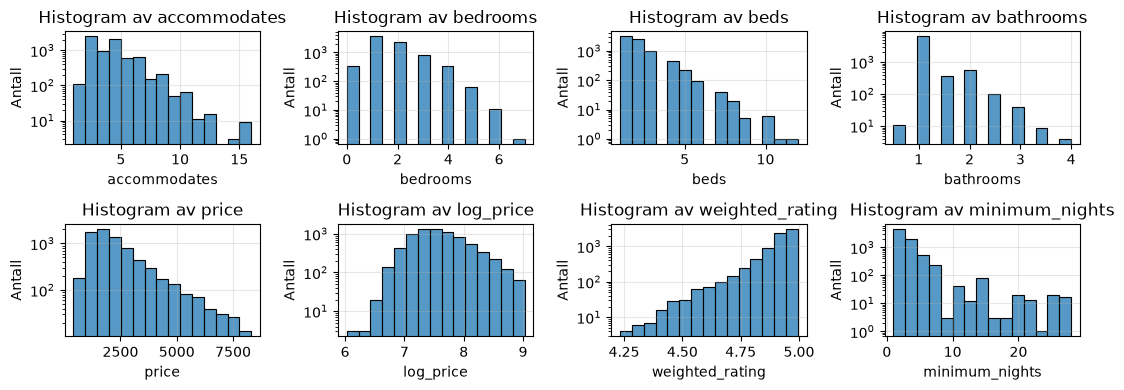

In [142]:
vars = ['accommodates', 'bedrooms', 'beds', 'bathrooms', 'price', 'log_price', 'weighted_rating', 'minimum_nights']

fig, axes = plt.subplots(2, 4, figsize=(11, 4))
axes = axes.flatten()

for ax, var in zip(axes, vars):
    sns.histplot(data=df_analyze, x=var, bins=15, ax=ax)
    ax.set_title(f"Histogram av {var}")
    ax.set_xlabel(var)
    ax.set_yscale('log')
    ax.set_ylabel("Antall")
    ax.grid(alpha=0.3)

plt.tight_layout()

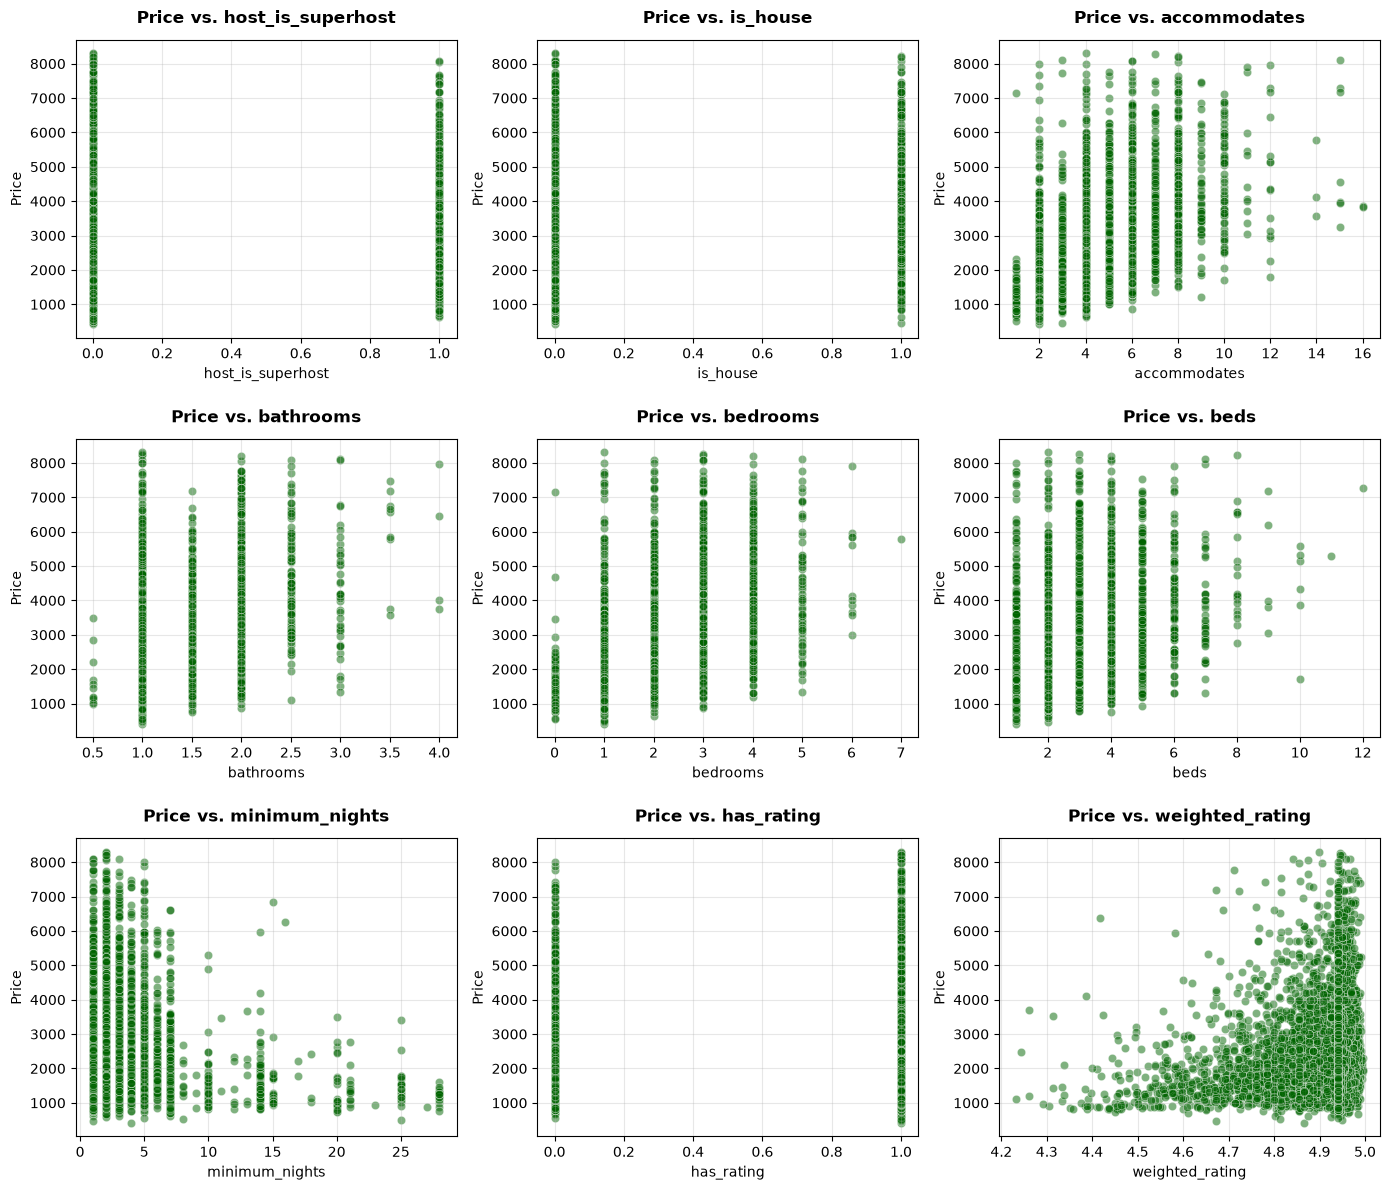

In [148]:
numeric_columns = ['host_is_superhost', 'is_house','accommodates','bathrooms', 'bedrooms', 'beds','minimum_nights', 'has_rating', 'weighted_rating']

columns_per_row = 3
rows = (len(numeric_columns) + columns_per_row - 1) // columns_per_row
fig, axes = plt.subplots(rows, columns_per_row, figsize=(14, 4 * rows), squeeze=False)
axes = axes.flatten()

for ax, column in zip(axes, numeric_columns):
    sns.scatterplot(data=df_analyze, x=column, y="price", color = 'darkgreen', ax=ax, alpha=0.5)
    ax.set_title(f"Price vs. {column}", fontweight="bold", pad=12)
    ax.set_xlabel(column)
    ax.set_ylabel("Price")
    ax.grid(alpha=0.3)

for ax in axes[len(numeric_columns):]:
    ax.remove()

plt.tight_layout(h_pad=2.0)

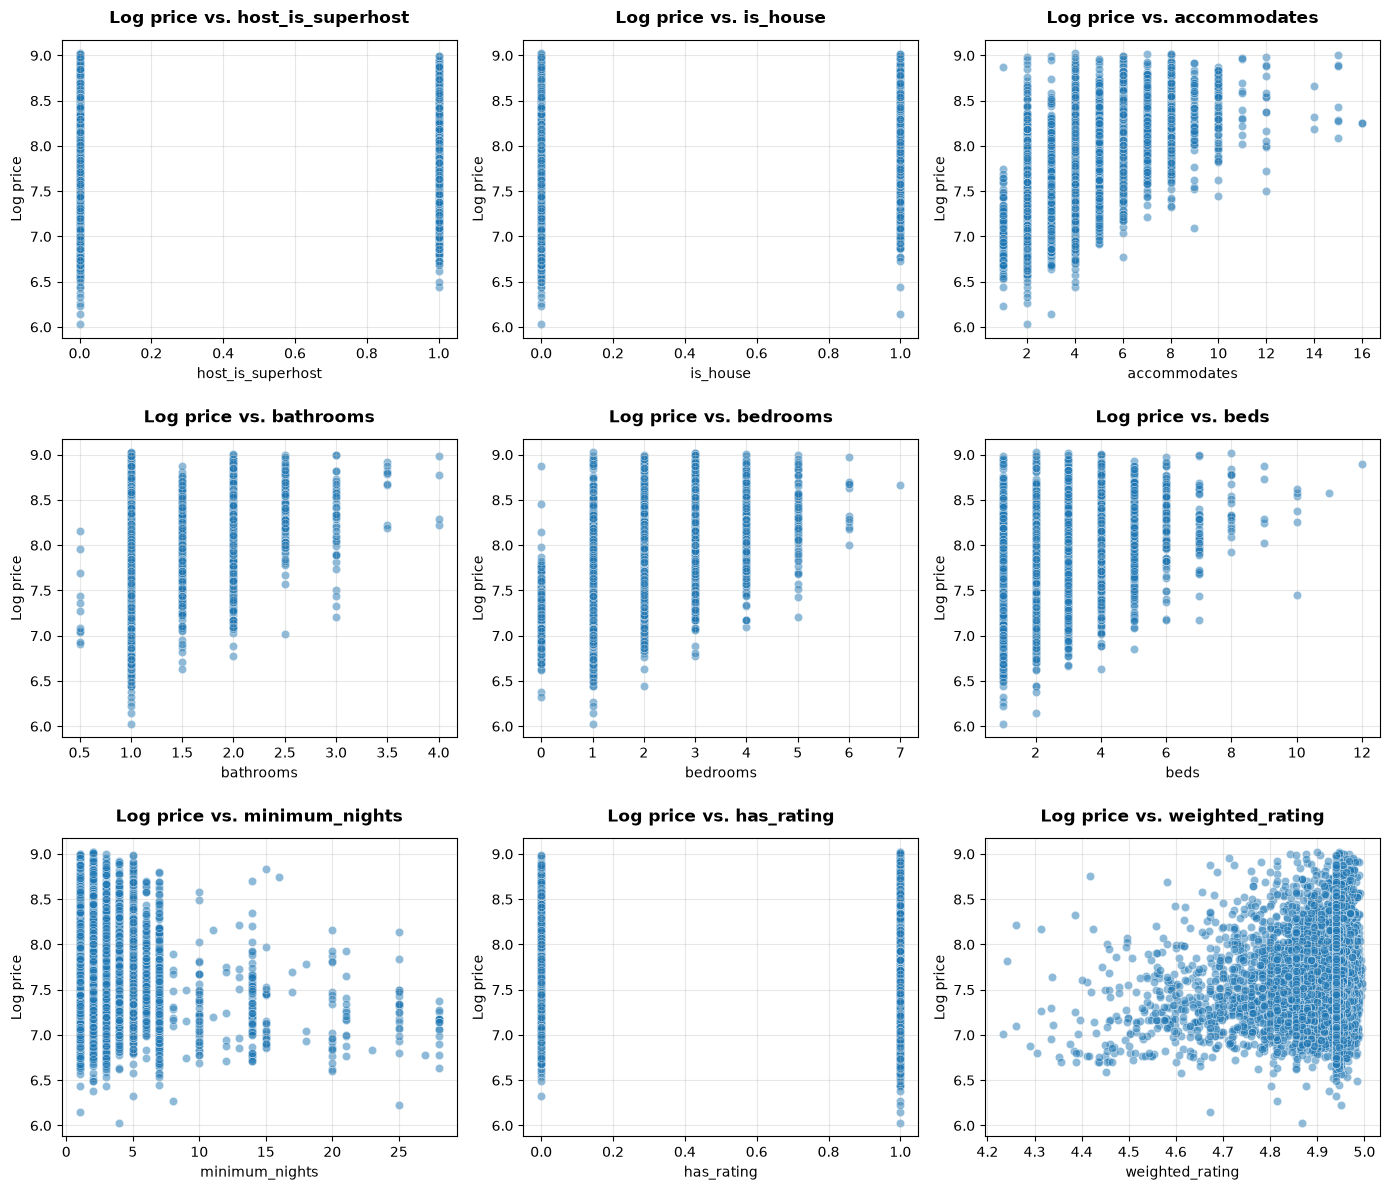

In [149]:
numeric_columns = ['host_is_superhost', 'is_house','accommodates','bathrooms', 'bedrooms', 'beds','minimum_nights', 'has_rating', 'weighted_rating']

columns_per_row = 3
rows = (len(numeric_columns) + columns_per_row - 1) // columns_per_row
fig, axes = plt.subplots(rows, columns_per_row, figsize=(14, 4 * rows), squeeze=False)
axes = axes.flatten()

for ax, column in zip(axes, numeric_columns):
    sns.scatterplot(data=df_analyze, x=column, y="log_price", ax=ax, alpha=0.5)
    ax.set_title(f"Log price vs. {column}", fontweight="bold", pad=12)
    ax.set_xlabel(column)
    ax.set_ylabel("Log price")
    ax.grid(alpha=0.3)

for ax in axes[len(numeric_columns):]:
    ax.remove()

plt.tight_layout(h_pad=2.0)

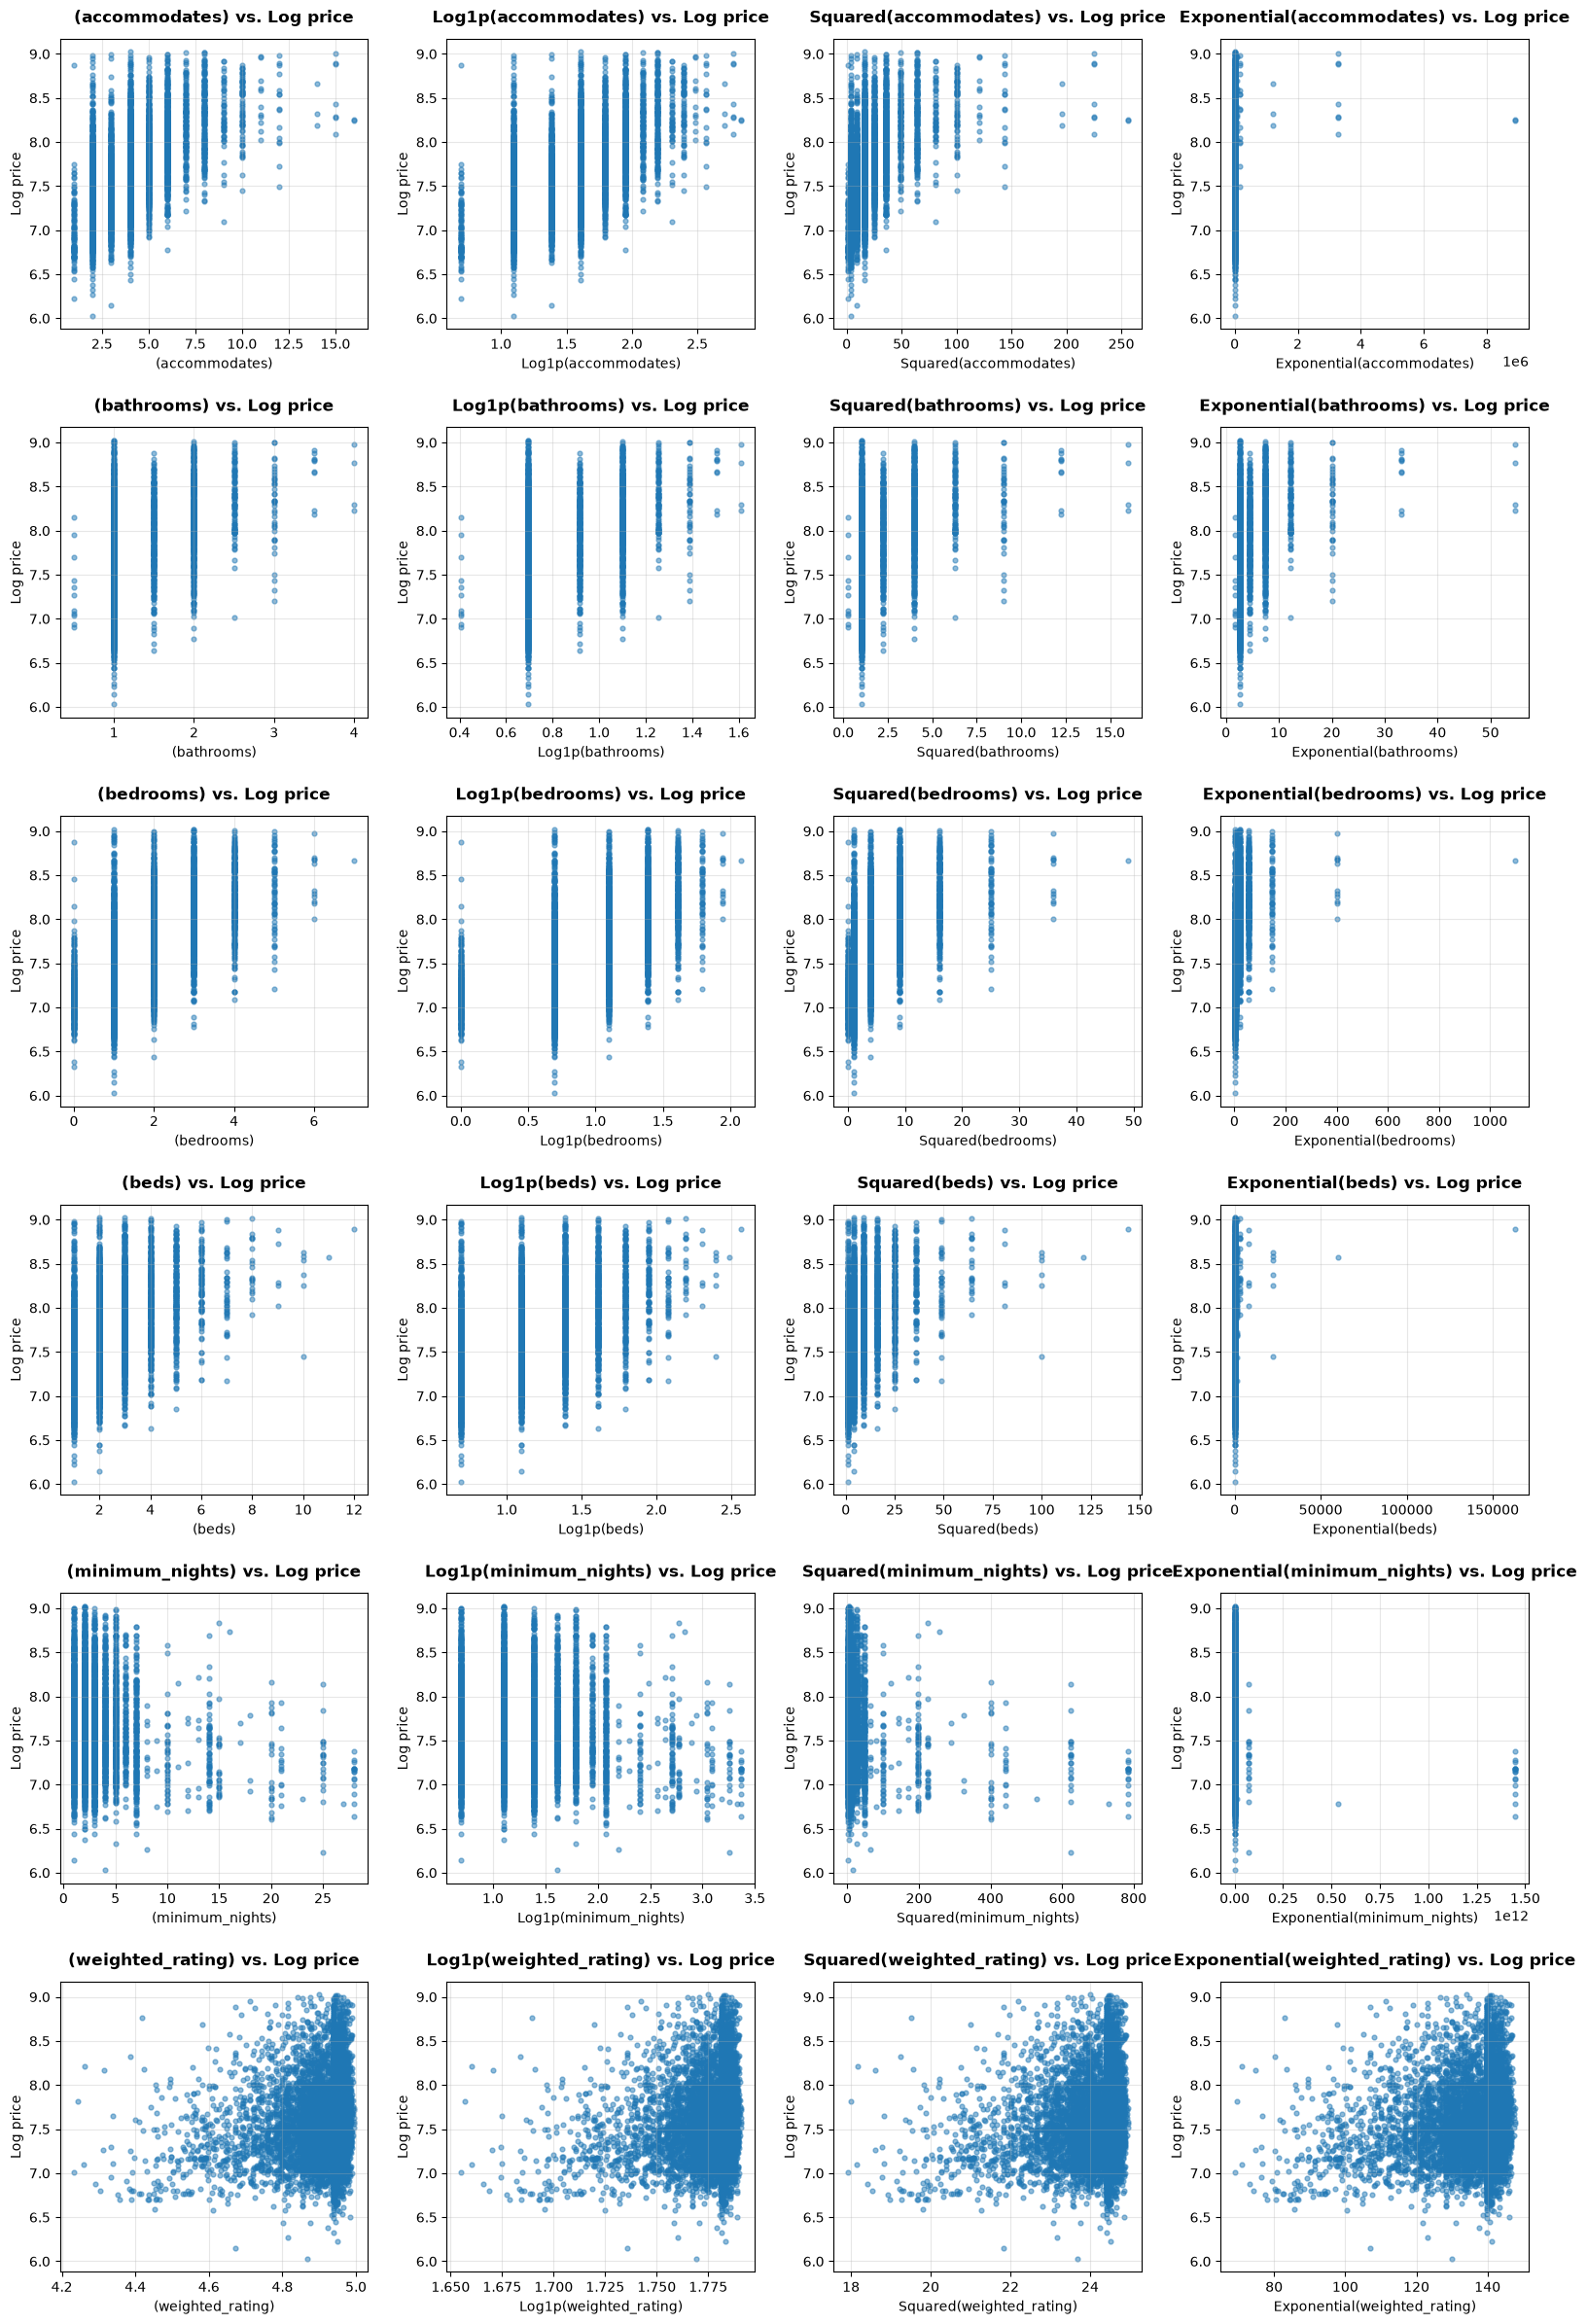

In [150]:
df_analyze["log_price"] = np.log(df_analyze["price"].where(df_analyze["price"] > 0))

scatter_features = ['accommodates','bathrooms', 'bedrooms', 'beds','minimum_nights', 'weighted_rating']

transformations = [
    ("", lambda values: values * 1),
    ("Log1p", np.log1p),
    ("Squared", lambda values: values ** 2),
    ("Exponential", np.exp),
]

rows = len(scatter_features)
fig, axes = plt.subplots(rows, 4, figsize=(16, 4 * rows), squeeze=False)

for row, column in enumerate(scatter_features):
    plot_data = df_analyze[[column, "log_price"]].dropna()
    for col, (transform_name, transform) in enumerate(transformations):
        transformed_values = transform(plot_data[column])
        valid = np.isfinite(transformed_values) & np.isfinite(plot_data["log_price"])
        ax = axes[row, col]
        ax.scatter(
            transformed_values[valid],
            plot_data.loc[valid, "log_price"],
            alpha=0.5,
            s=12,
        )
        ax.set_title(
            f"{transform_name}({column}) vs. Log price",
            fontweight="bold",
            pad=12,
        )
        ax.set_xlabel(f"{transform_name}({column})")
        ax.set_ylabel("Log price")
        ax.grid(alpha=0.3)

plt.tight_layout(h_pad=2.0)

could be useful to use the transformed variables for accommodates, beds and minimumnights to compensate for a bit of a rights skew in the data. dont need to use log1 as non of them have 0 values

In [151]:
columns = ['accommodates', 'beds', 'minimum_nights']
for col in columns:
    df_analyze[f'{col}_log'] = np.log(df_analyze[col])

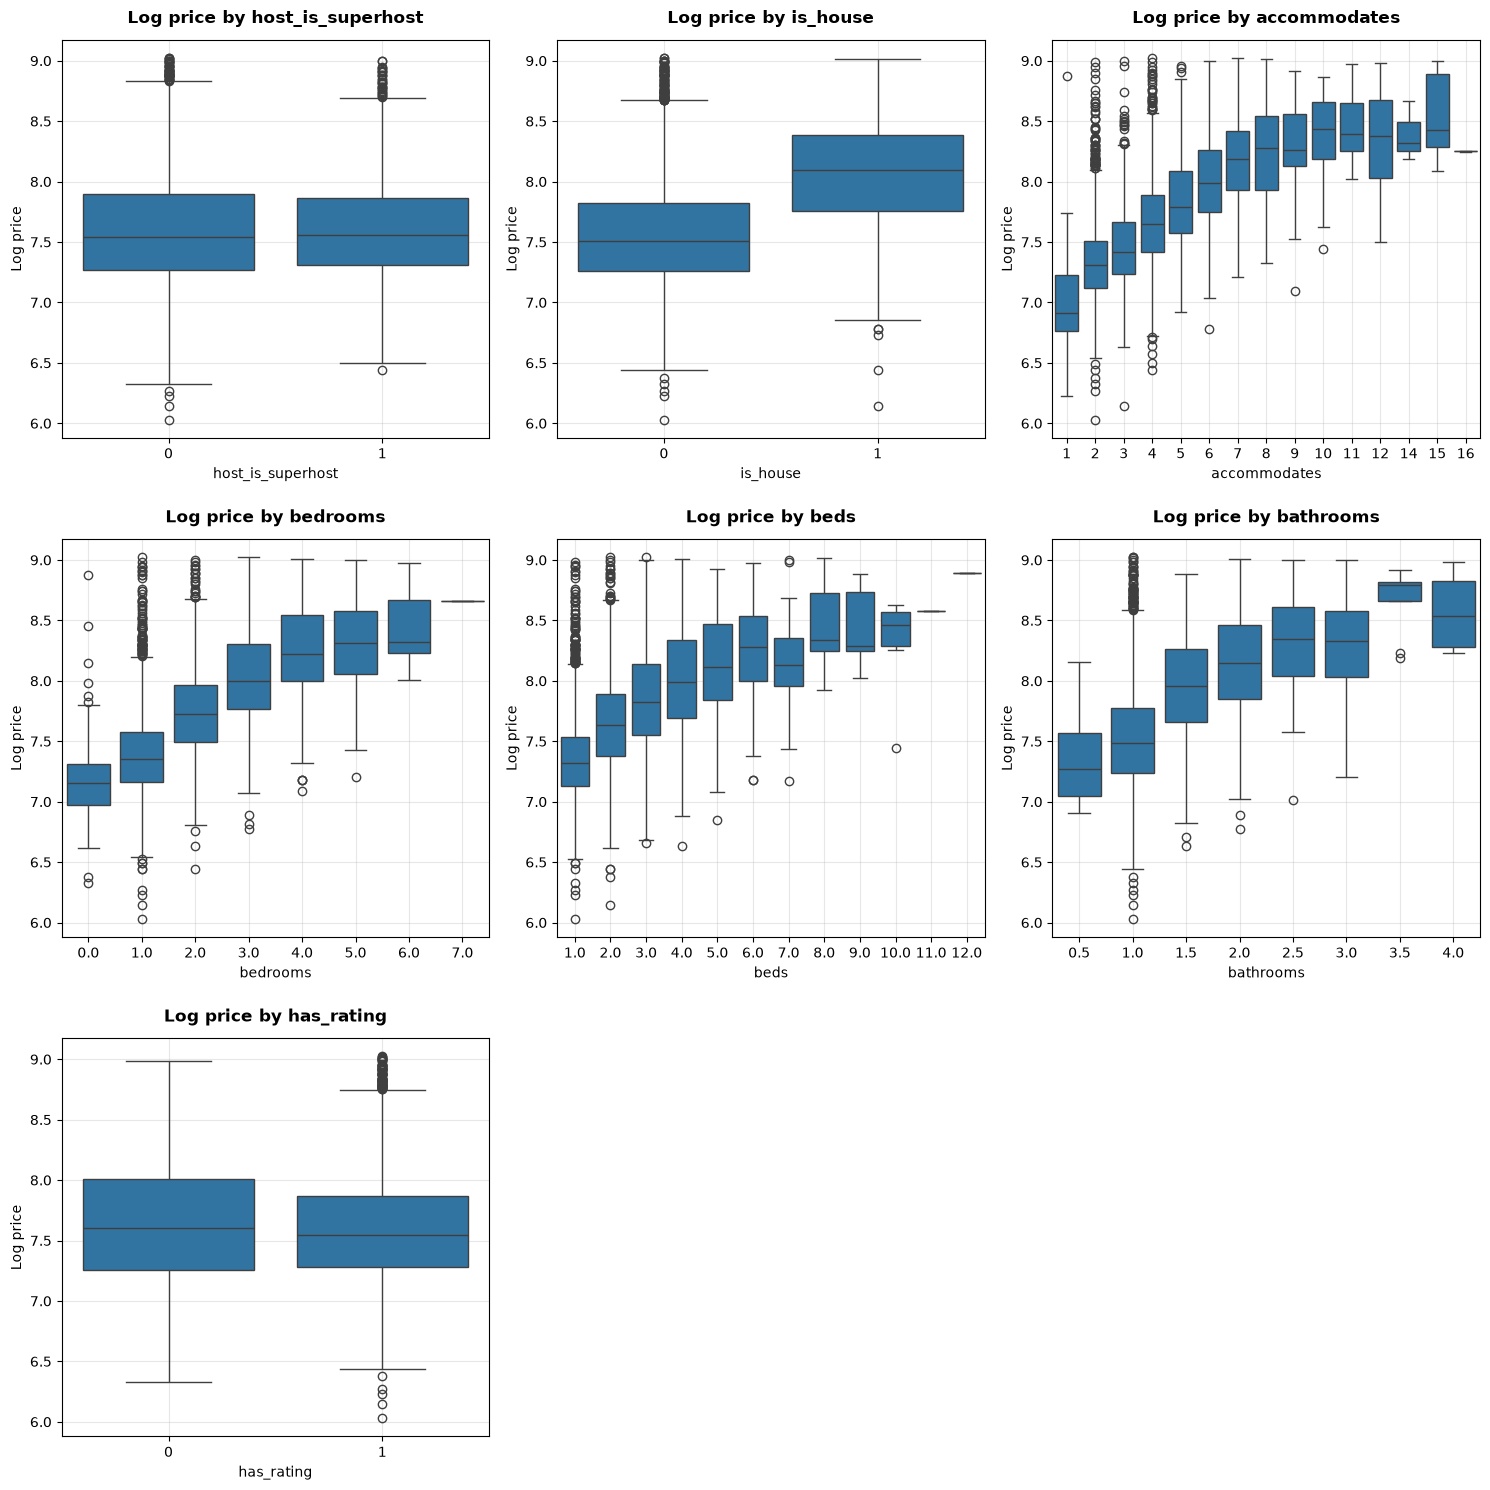

In [152]:
numeric_columns = ['host_is_superhost', 'is_house', 'accommodates', 'bedrooms', 'beds', 'bathrooms', 'has_rating']

columns_per_row = 3
rows = (len(numeric_columns) + columns_per_row - 1) // columns_per_row
fig, axes = plt.subplots(rows, columns_per_row, figsize=(15, 5 * rows), squeeze=False)
axes = axes.flatten()

for ax, column in zip(axes, numeric_columns):
    sns.boxplot(data=df_analyze, x=column, y="log_price", ax=ax)
    ax.set_title(f"Log price by {column}", fontweight="bold", pad=12)
    ax.set_xlabel(column)
    ax.set_ylabel("Log price")
    ax.grid(alpha=0.3)

for ax in axes[len(numeric_columns):]:
    ax.remove()

plt.tight_layout(h_pad=2.0)

se på relasjonen mellom de ulike variablene ved et heatmap

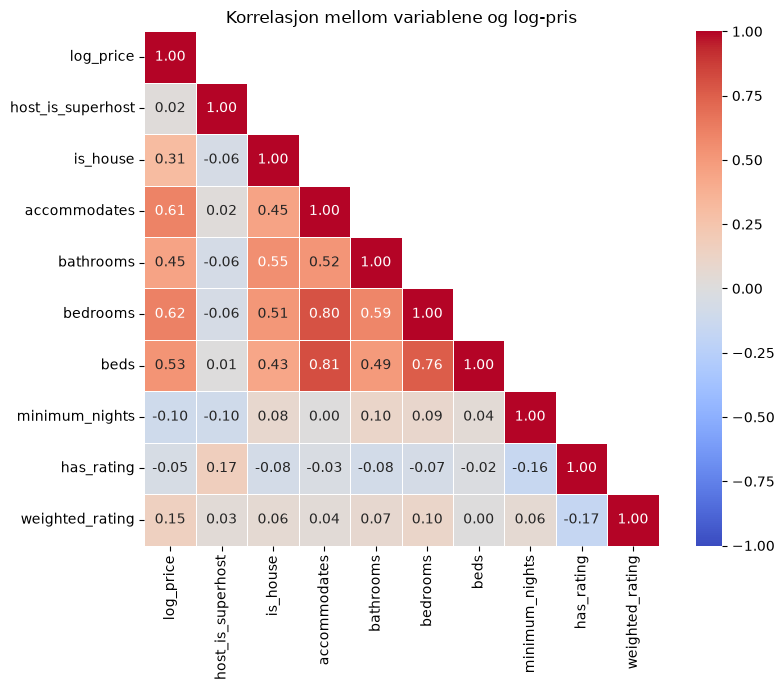

In [153]:
heatmap_columns = [
    'log_price',
    'host_is_superhost', 'is_house', 'accommodates', 'bathrooms',
    'bedrooms', 'beds', 'minimum_nights', 'has_rating', 'weighted_rating'
]

correlation_matrix = df_analyze[heatmap_columns].corr()

# Skjul øvre trekant (speilbilde av nedre)
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool), k=1)

plt.figure(figsize=(9, 7))
sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1, center=0,
    linewidths=0.5,
    square=True,
)
plt.title("Korrelasjon mellom variablene og log-pris")
plt.tight_layout()
plt.show()

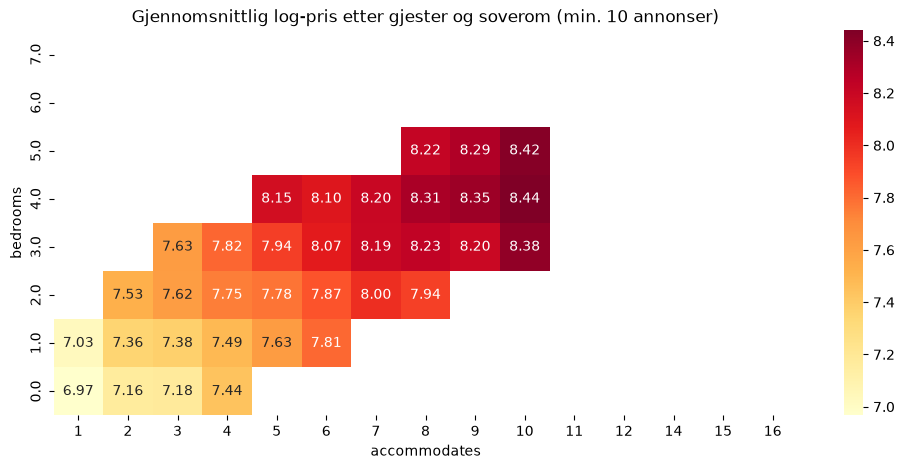

In [ ]:
pivot_mean = df_analyze.pivot_table(index="bedrooms", columns="accommodates",
                                  values="log_price", aggfunc="mean")
pivot_count = df_analyze.pivot_table(index="bedrooms", columns="accommodates",
                                   values="log_price", aggfunc="count")

plt.figure(figsize=(12, 5))
ax = sns.heatmap(pivot_mean.where(pivot_count >= 8),
                 annot=True, fmt=".2f", cmap="YlOrRd")
ax.invert_yaxis()   # flere soverom oppover
plt.title("Gjennomsnittlig log-pris etter gjester og soverom (min. 10 annonser)")
plt.show()

looks like the number of bedrooms can have a say in the price even with the same value for accommodates

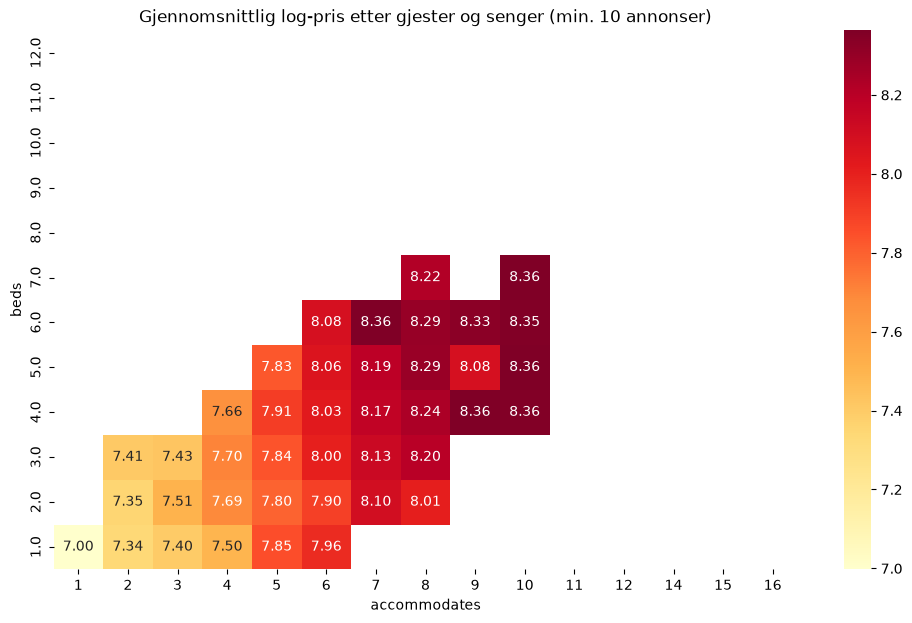

In [ ]:
pivot_mean = df_analyze.pivot_table(index="beds", columns="accommodates",
                                  values="log_price", aggfunc="mean")
pivot_count = df_analyze.pivot_table(index="beds", columns="accommodates",
                                   values="log_price", aggfunc="count")

plt.figure(figsize=(12, 7))
ax = sns.heatmap(pivot_mean.where(pivot_count >= 8),
                 annot=True, fmt=".2f", cmap="YlOrRd")
ax.invert_yaxis()   # flere soverom oppover
plt.title("Gjennomsnittlig log-pris etter gjester og senger (min. 10 annonser)")
plt.show()

the effect of beds given number of accommodates is not as siginificant as for bedrooms so we should drop beds and keep bedrooms

In [ ]:
df_analyze = df_analyze.drop(columns=['beds', 'beds_log]')

neighbourhood_cleansed
Grünerløkka          1419
Gamle Oslo           1288
Frogner              1115
St. Hanshaugen        870
Sagene                796
Nordstrand            348
Nordre Aker           284
Vestre Aker           247
Ullern                229
Østensjø              189
Bjerke                184
Sentrum               139
Alna                  116
Søndre Nordstrand      83
Grorud                 43
Stovner                31
Marka                  28
Name: count, dtype: int64


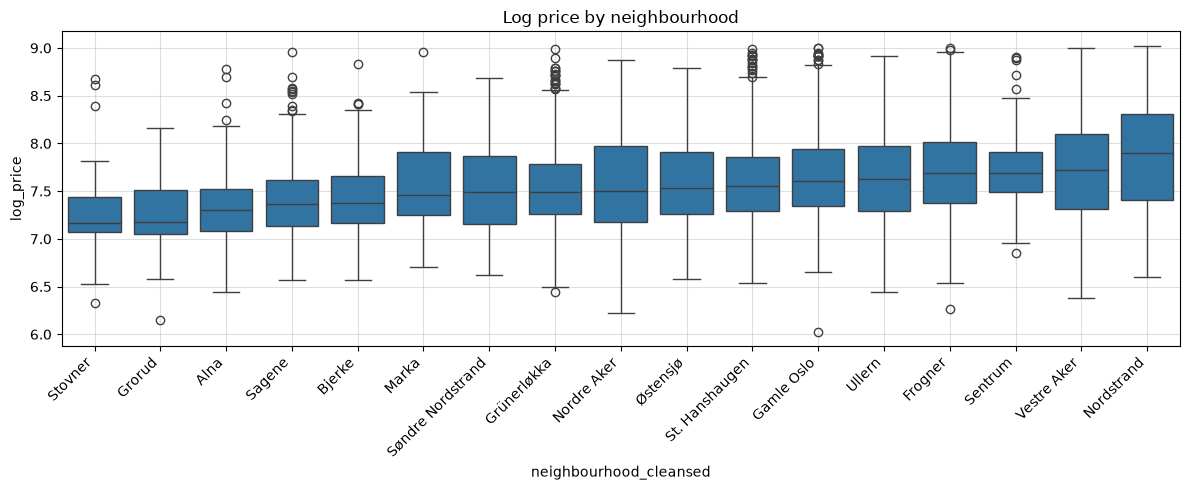

In [ ]:
order = df_analyze.groupby("neighbourhood_cleansed")["log_price"].median().sort_values().index

plt.figure(figsize=(12, 5))
sns.boxplot(data=df_analyze, x="neighbourhood_cleansed", y="log_price", order=order)
plt.xticks(rotation=45, ha="right")
plt.title("Log price by neighbourhood")
plt.tight_layout()
plt.grid(alpha = 0.4)

print(df_analyze["neighbourhood_cleansed"].value_counts())   # check group sizes

In [ ]:

listings_model = df_analyze.copy()
listings_model.to_csv(project_root / "data" / "processed" / "listings_model.csv", index=False)

,host_is_superhost,neighbourhood_cleansed,is_house,accommodates,bedrooms,beds,bathrooms,price,minimum_nights,log_price,has_rating,weighted_rating,accommodates_log,beds_log,minimum_nights_log
0,1,Nordstrand,0,6,2.0,3.0,1.0,1586.00,1.0,7.368970,1,4.959613,1.791759,1.098612,0.000000
1,0,Sagene,0,2,1.0,1.0,1.0,1114.13,15.0,7.015829,1,4.897647,0.693147,0.000000,2.708050
2,0,Grünerløkka,0,2,1.0,1.0,1.0,1280.15,3.0,7.154733,1,4.684595,0.693147,0.000000,1.098612
3,0,Grünerløkka,0,5,4.0,3.0,1.5,3700.00,4.0,8.216088,1,4.920000,1.609438,1.098612,1.386294
4,0,Grünerløkka,0,2,1.0,1.0,1.0,1702.00,3.0,7.439559,1,4.910256,0.693147,0.000000,1.098612
